<span style="font-family:monospace;letter-spacing:.14em;color:#857259">BANA · MODULE 2 · EXPLORING AND VISUALISING DATA</span>

# Session 4: Choose the right chart and tell the story

**Dataset:** EV purchase intention (Kaggle Playground Series S6E9, a *synthetic* dataset). You work with a 10,000-row seeded sample, `ev_m2_sample.csv`.
**Time:** 60 minutes. **Course outcomes:** CO2 (and CO3 for Session 5).

| Block | Min | What you do |
|---|---|---|
| Hook | 5 | Berkeley: the wrong grouping tells the wrong story |
| Concept | 10 | Which chart for which question (instructor) |
| Guided lab | 30 | Build four charts, write a headline for each |
| Team task | 10 | Chart-off: fix a misleading chart |
| Exit ticket | 5 | Three quick checks |

**By the end of this session you can:**
- match a question to a chart type
- build four charts and give each a one-sentence headline
- spot a misleading axis and fix it
- explain why a group difference can disappear when you split the data

**New commands this session (max 5):** grouped bar, `sns.lineplot`, `pivot_table`, `sns.heatmap`, titles and labels

**AI-use (AMBER protocol).** You may use an AI tool to look up *syntax*. The reasoning and interpretation must be your own: you will defend them in the viva.

## Facilitator notes: Session 4
**Question for the room:** *Which chart answers which question?*

**Run of show**
1. **Hook (5):** tell the Berkeley admissions story (Bickel, Hammel & O'Connell, 1975): overall, men were admitted at a higher rate, but within most departments women were admitted at equal or higher rates. The grouping changed the conclusion. Then say: *we have a smaller version of this in our data.*
2. **Concept (10):** chart-choice rule: **compare categories → bar; trend → line; spread → histogram or box; two numbers → scatter; two categories and a rate → heatmap.** People read position and length more accurately than area or colour (Cleveland & McGill, 1984). One headline per chart; remove clutter (Knaflic, 2015).
3. **Lab (30):** four charts. Chart 2 is the star.
4. **Chart-off (10):** score on clear question, right chart, clear takeaway (0-2 each).

**The story in this data (all numbers from the 10,000-row sample)**
- **Chart 1:** Rural 21.6% > Suburban 18.5% > Urban 16.4%. Students will say 'rural people prefer EVs'.
- **Chart 2:** home charging is available to 97% of rural, 90% of suburban and only 40% of urban households. Among people who **can** charge at home, the Yes rate is about the same everywhere: Rural 22.0%, Suburban 19.7%, Urban 20.6%. So the city gap is mostly a *home charging* gap. Be honest: this is not a full Simpson reversal, it is **confounding**: the headline changes once you split the data.
- **Chart 3:** where there is no subsidy almost nobody says Yes (0.6% vs 28.5% with a subsidy), and environmental concern lifts the rate steeply only when a subsidy exists.
- **Chart 4:** the Yes rate climbs with both income and concern.

**Warn about** the Rural / no-home-charging bar: only 55 rows, so it is shaky. Make students put n on the chart.

In [1]:
# -- Setup: run once ------------------------------------------------------
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
warnings.filterwarnings("ignore")

# House style: Nikhil D Jonathan design system (sand ground, terracotta / lagoon / ochre data colours)
C = {"lagoon": "#25707B", "terracotta": "#B5562F", "ochre": "#E0A231", "moss": "#3F6F4B",
     "earth": "#665643", "ink": "#221B15", "sand": "#F8F3EA", "card": "#FFFDF9", "line": "#E3D6C1"}
sns.set_theme(style="whitegrid", rc={
    "figure.facecolor": C["sand"], "axes.facecolor": C["card"], "axes.edgecolor": "#CDBCA3",
    "grid.color": C["line"], "text.color": C["ink"], "axes.labelcolor": C["ink"],
    "xtick.color": "#4A3E31", "ytick.color": "#4A3E31", "axes.spines.top": False,
    "axes.spines.right": False, "figure.dpi": 100, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left"})
PCT = PercentFormatter(1, decimals=0)                              # axis labels as percentages
SEQ = sns.light_palette(C["terracotta"], as_cmap=True)   # one-hue sequential map for heatmaps

# -- Load the data (Colab: upload ev_m2_sample.csv to the Files pane, or run the upload below)
FILE = "ev_m2_sample.csv"
if not os.path.exists(FILE):
    try:
        from google.colab import files
        print("Choose ev_m2_sample.csv"); files.upload()
    except ImportError:
        raise FileNotFoundError("Put ev_m2_sample.csv in the same folder as this notebook.")
raw = pd.read_csv(FILE)
df = raw.copy()
print("Loaded", df.shape[0], "rows x", df.shape[1], "columns")

Loaded 10000 rows x 15 columns


## Part A. Setup

In [2]:
def add_derived(d):
    """The four derived columns built in Session 1 (pre-written so every notebook stands alone)."""
    d = d.copy()
    d["buy"] = (d["Will_Buy_EV"] == "Yes").astype(int)
    d["age_band"] = pd.cut(d["Age"], bins=[24, 34, 44, 54, 69], labels=["25-34", "35-44", "45-54", "55-69"])
    d["income_band"] = pd.qcut(d["Annual_Income_USD"], 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"])
    d["charger_total"] = d["Charging_Stations_Near_Home"] + d["Charging_Stations_Near_Work"]
    return d

In [3]:
def apply_s3_decisions(d):
    """Session 3 data-quality decisions, applied in one place (see your decision log)."""
    d = d.copy()
    d["income_was_missing"] = d["Annual_Income_USD"].isna()
    d["Annual_Income_USD"] = d["Annual_Income_USD"].fillna(d.groupby("City_Type")["Annual_Income_USD"].transform("median"))
    d["Daily_Commute_km"] = d["Daily_Commute_km"].fillna(d["Daily_Commute_km"].median())
    d = d.dropna(subset=["Environmental_Concern_Level"])      # strongest signal: do not blur it with a median
    d["income_at_floor"] = d["Annual_Income_USD"] == 30000
    d["commute_at_floor"] = d["Daily_Commute_km"] == 5
    return d

df = add_derived(apply_s3_decisions(raw))     # the Session 3 decisions, pre-applied
df["Subsidy"] = df["Subsidy_Available"].map({"Yes": "Subsidy", "No": "No subsidy"})
print(df.shape)

(9806, 23)


## The chart rule (read, 3 min)
| Your question | Chart |
|---|---|
| How does a rate compare across categories? | **bar** (start the axis at 0) |
| How does a rate change across an ordered scale? | **line** |
| How are values spread? | **histogram / box** |
| How do two numbers move together? | **scatter** |
| How does a rate depend on two categories? | **heatmap** |

Every chart gets: a **question**, the **right chart**, one **headline** that says the finding.

## Chart 1. Which city type buys most?

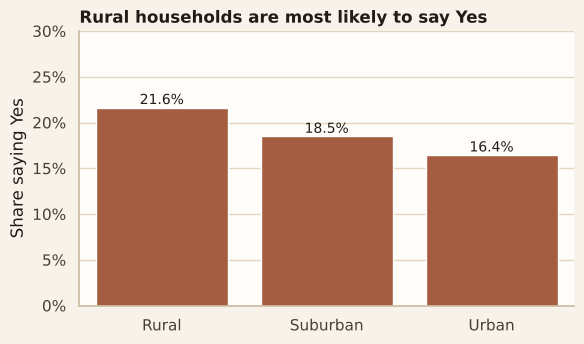

In [4]:
rate = df.groupby("City_Type")["buy"].mean().reindex(["Rural", "Suburban", "Urban"])
n = df["City_Type"].value_counts()
fig, ax = plt.subplots(figsize=(6, 3.6))
sns.barplot(x=rate.index, y=rate.values, color=C["terracotta"], ax=ax)
for i, c in enumerate(rate.index):
    ax.text(i, rate[c] + 0.004, f"{rate[c]:.1%}", ha="center", fontsize=10)
ax.set_ylim(0, 0.30); ax.set_ylabel("Share saying Yes"); ax.yaxis.set_major_formatter(PCT); ax.set_xlabel("")
ax.set_title("Rural households are most likely to say Yes")
plt.tight_layout()

## Chart 2. Is it the city, or something else? (the star chart)
**Predict first:** if you split each city by *home charging possible*, will the city gaps stay?

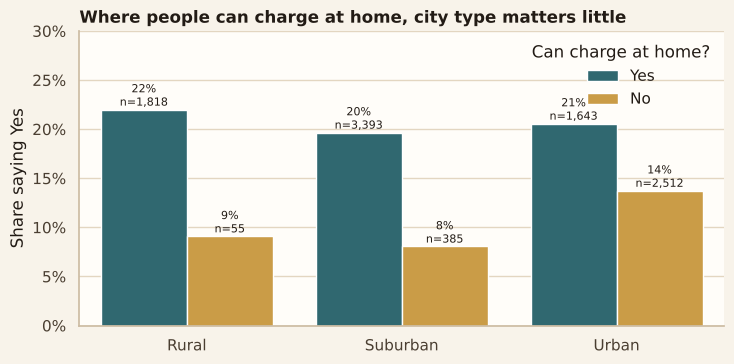

In [5]:
g = df.groupby(["City_Type", "Home_Charging_Possible"])["buy"].agg(rate="mean", n="size").reset_index()
fig, ax = plt.subplots(figsize=(7.5, 3.8))
sns.barplot(data=g, x="City_Type", y="rate", hue="Home_Charging_Possible", order=["Rural", "Suburban", "Urban"],
            hue_order=["Yes", "No"], palette={"Yes": C["lagoon"], "No": C["ochre"]}, ax=ax)
for p, (_, row) in zip(ax.patches, g.sort_values(["Home_Charging_Possible", "City_Type"], key=lambda s: s.map({"Yes": 0, "No": 1, "Rural": 0, "Suburban": 1, "Urban": 2})).iterrows()):
    ax.text(p.get_x() + p.get_width() / 2, p.get_height() + 0.004, f"{p.get_height():.0%}\nn={int(row['n']):,}", ha="center", fontsize=8)
ax.set_ylim(0, 0.30); ax.set_ylabel("Share saying Yes"); ax.yaxis.set_major_formatter(PCT); ax.set_xlabel("")
ax.legend(title="Can charge at home?", frameon=False)
ax.set_title("Where people can charge at home, city type matters little")
plt.tight_layout()

In [6]:
# How common is home charging in each city type?
(df["Home_Charging_Possible"] == "Yes").groupby(df["City_Type"]).mean().round(2)

City_Type
Rural       0.97
Suburban    0.90
Urban       0.40
Name: Home_Charging_Possible, dtype: float64

**YOUR ANSWER:** Chart 1 said 'rural people prefer EVs'. What does Chart 2 say instead? Write the corrected headline for the marketing head.

> _write here_

## Chart 3. How much do subsidy and environmental concern matter?

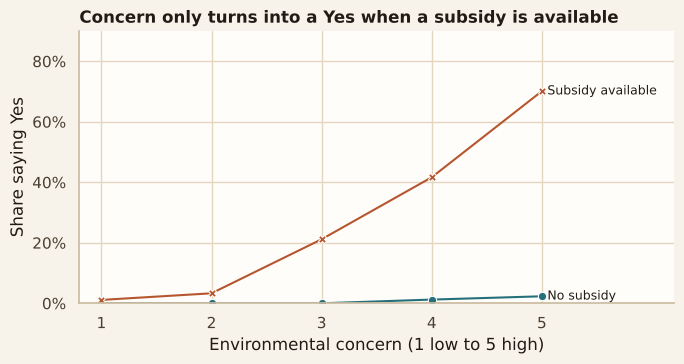

In [7]:
rate = df.groupby(["Environmental_Concern_Level", "Subsidy"])["buy"].mean().reset_index()
fig, ax = plt.subplots(figsize=(7, 3.8))
sns.lineplot(data=rate, x="Environmental_Concern_Level", y="buy", hue="Subsidy", style="Subsidy", markers=True, dashes=False,
             palette={"Subsidy": C["terracotta"], "No subsidy": C["lagoon"]}, ax=ax, legend=False)
ax.text(5.05, rate[(rate.Subsidy == "Subsidy") & (rate.Environmental_Concern_Level == 5)]["buy"].iloc[0], "Subsidy available", color=C["ink"], va="center", fontsize=9)
ax.text(5.05, rate[(rate.Subsidy == "No subsidy") & (rate.Environmental_Concern_Level == 5)]["buy"].iloc[0], "No subsidy", color=C["ink"], va="center", fontsize=9)
ax.set_xlim(0.8, 6.2); ax.set_xticks([1, 2, 3, 4, 5]); ax.set_ylim(0, 0.9)
ax.set_xlabel("Environmental concern (1 low to 5 high)"); ax.set_ylabel("Share saying Yes"); ax.yaxis.set_major_formatter(PCT)
ax.set_title("Concern only turns into a Yes when a subsidy is available")
plt.tight_layout()

## Chart 4. Income and concern together (heatmap)

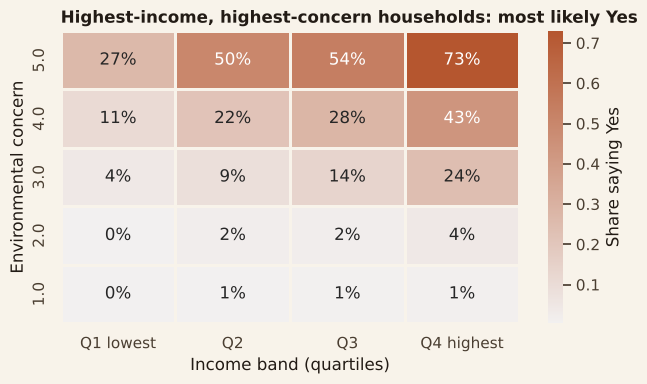

In [8]:
pt = df.pivot_table(values="buy", index="Environmental_Concern_Level", columns="income_band", aggfunc="mean", observed=True)
pt = pt.sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(6.6, 4))
sns.heatmap(pt, annot=True, fmt=".0%", cmap=SEQ, cbar_kws={"label": "Share saying Yes"}, linewidths=2, linecolor=C["sand"], ax=ax)
ax.set_xlabel("Income band (quartiles)"); ax.set_ylabel("Environmental concern")
ax.set_title("Highest-income, highest-concern households: most likely Yes")
plt.tight_layout()

## Chart-off (10 min)
Below is a chart a junior analyst sent to the marketing head. **Find three problems, then redraw it.**

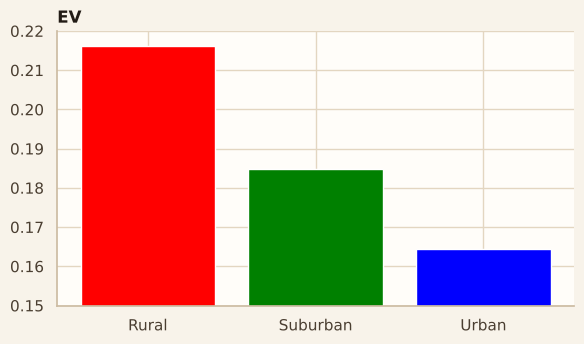

In [9]:
def weak_chart():
    r = df.groupby("City_Type")["buy"].mean()
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.bar(r.index, r.values, color=["red", "green", "blue"])
    ax.set_ylim(0.15, 0.22)
    ax.set_title("EV")
    plt.tight_layout()
weak_chart()

**Problems you found (list three):**

> 1. 
> 2. 
> 3. 

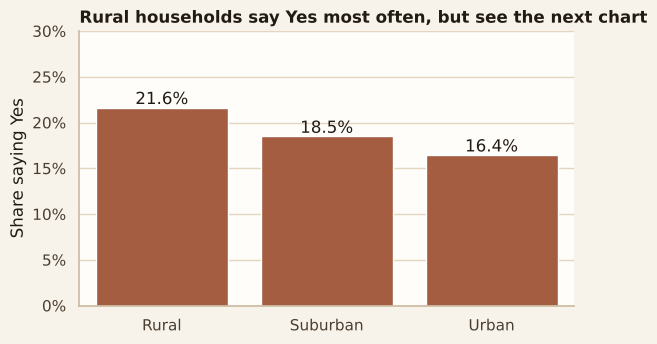

In [10]:
def better_chart():
    r = df.groupby("City_Type")["buy"].mean().reindex(["Rural", "Suburban", "Urban"])
    fig, ax = plt.subplots(figsize=(6, 3.6))
    sns.barplot(x=r.index, y=r.values, color=C["terracotta"], ax=ax)
    for i, c in enumerate(r.index):
        ax.text(i, r[c] + 0.004, f"{r[c]:.1%}", ha="center")
    ax.set_ylim(0, 0.30); ax.set_ylabel("Share saying Yes"); ax.yaxis.set_major_formatter(PCT); ax.set_xlabel("")
    ax.set_title("Rural households say Yes most often, but see the next chart")
    plt.tight_layout()
better_chart()

**Score your team's chart (0-2 each):** clear question __ · right chart __ · clear takeaway __ · **total /6**

**Expected problems:** (1) y-axis starts at 15%, so a 3-point gap looks huge (truncated axis; Pandey et al., 2015); (2) three arbitrary colours that carry no meaning; (3) no title that states a finding, no axis label, no values, no n.

## Output: your four-chart mini-story
For each chart, one sentence a marketing head can use. Then save the charts.

In [11]:
story = pd.DataFrame({
    "chart": ["1 City", "2 City x home charging", "3 Concern x subsidy", "4 Income x concern"],
    "headline": ["", "", "", ""],      # TODO: fill four headlines
})
story

,chart,headline
0,1 City,
1,2 City x home charging,
2,3 Concern x subsidy,
3,4 Income x concern,


## Exit ticket (5 min)
1. Which chart would you use to compare Yes rates across five income bands, and why not a pie?
2. Chart 1 and Chart 2 gave different headlines. Which one should the marketing head see, and what does Chart 1 do wrong?
3. Why print n on a bar?

**Answers:** (1) bar (or line if the bands are ordered); pie slices are hard to compare; (2) Chart 2: Chart 1 pools two groups (home chargers and non-chargers) that differ in size across cities; (3) so the reader can judge how much to trust a percentage, especially for small groups (Rural / no home charging n = 55).

**Viva prompt (AMBER):** "Why does your Chart 2 headline say something different from Chart 1? Prove it with a number."

### References (facilitator only)
Bickel, P. J., Hammel, E. A., & O'Connell, J. W. (1975). Sex bias in graduate admissions: Data from Berkeley. *Science*, 187(4175), 398-404.
Cleveland, W. S., & McGill, R. (1984). Graphical perception. *Journal of the American Statistical Association*, 79(387), 531-554.
Knaflic, C. N. (2015). *Storytelling with Data*. Wiley.
Pandey, A. V., Rall, K., Satterthwaite, M. L., Nov, O., & Bertini, E. (2015). How deceptive are deceptive visualizations? *Proceedings of CHI 2015*. ACM.
Wickham, H. (2010). A layered grammar of graphics. *Journal of Computational and Graphical Statistics*, 19(1), 3-28.